Solution of the robust performance problem via $\mu$-synthesis.

Example from Skogestad & Postlethwaite 8.12.4
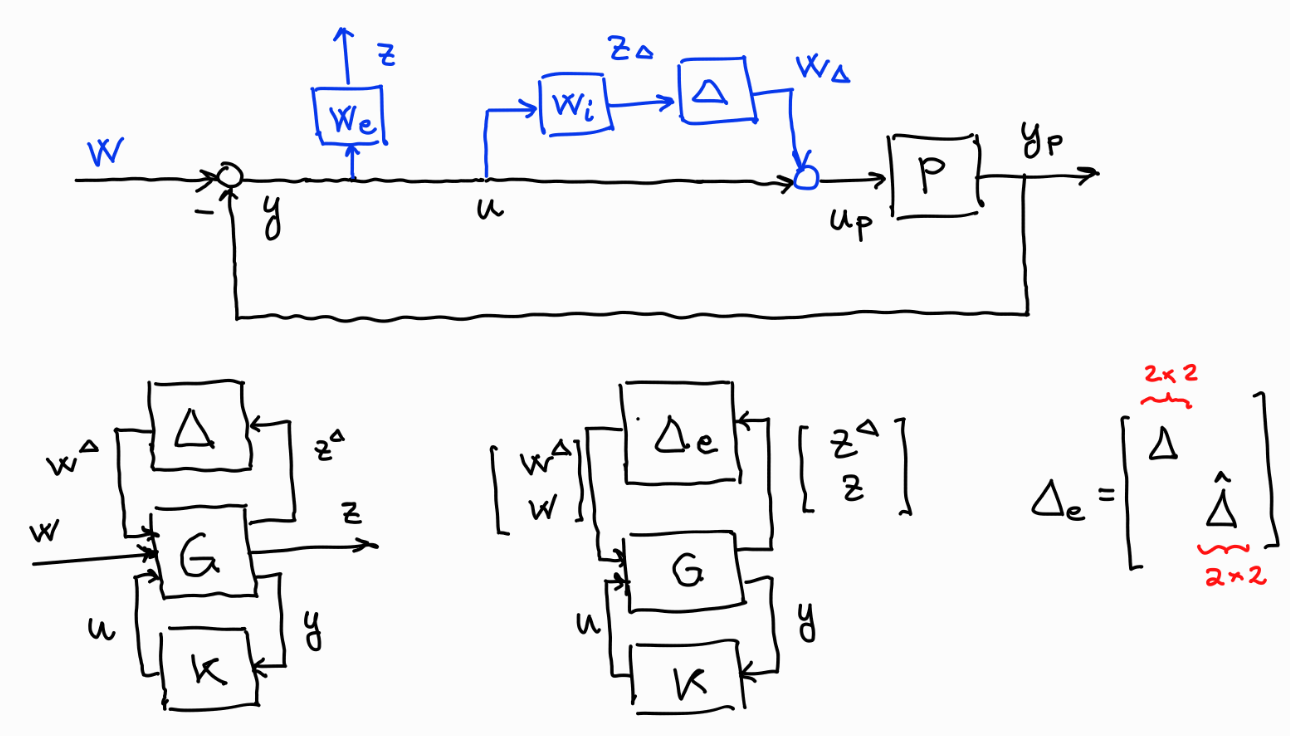

Plant uncertainty model is $P_p=P(I+\Delta W_i)$, with $W_i=w_i I$.

In [1]:
import matplotlib.pyplot as plt
from itertools import product
import slycot as sly
import numpy as np
import control as ct
import rpc_diism.robust as rb
import logging
import dkpy

In [2]:
# Plant P
den = [75, 1]
P = ct.tf([[[87.8], [-86.4]],
              [[108.2], [-109.6]]],
             [[den, den],
              [den, den]])
display("Plant transfer function", P)

# Frequency range for all computations
omega = np.logspace(-3, 3, 81)

'Plant transfer function'

TransferFunction(
[[array([87.8]), array([-86.4])],
 [array([108.2]), array([-109.6])]],
[[array([75,  1]), array([75,  1])],
 [array([75,  1]), array([75,  1])]],
outputs=2, inputs=2)

We assume that the uncertain plant has both gain and dynamics uncertainty. On each channel we assume an uncertain gain of $1+g$ where $g=\pm 0.2$ and an approximate neglected delay of $\tau\leq \tau_{max}=0.5$. The delay is approximated with a rational (Pade) transfer function $\frac{1-\tau/2 s}{1+\tau/2 s}$. Hence, the perturbed system will be $P_p=PH$ where $H= \frac{(1+g)(1-\tau/2 s)}{1+\tau/2 s} I$. To construct the uncertainty model, we construct the perturbed plant $P_p$ for various values of the uncertain parameters, and then we find a filter $W_i$ whose frequency response upper bounds $\bar\sigma(P^{-1}P_p-I$)

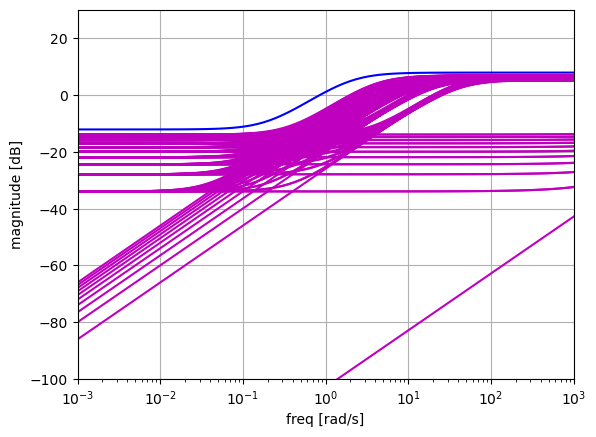

In [3]:
# Identity system
I = ct.ss([],[],[],np.eye(2))

# Construct various realizations of the uncertain parameters
for i in range(11):
    for j in range(-10,11):
        tau = 1/20*i
        g = 0.02*j
        # Construct the perturbation
        H = ct.tf([[[-tau/2*(1+g),1+g], [0]],
                  [[0], [-tau/2*(1+g),1+g]]],
                 [[[tau/2,1], [1]],
                  [[1], [tau/2,1]]])
        # Perturbed plant
        Pp = P * H
        # We need the inverse of P: to compute it we introduce a slight feedthrough to make it bi-proper
        Pinv = rb.invss(ct.ss(ct.tf([[[0.00001,87.8], [-86.4]],
                                    [[108.2], [0.00001,-109.6]]],
                                    [[den, den],
                                    [den, den]])))
        DeltaHat = Pinv * Pp - I

        # Compute the singular value plot of DeltaHat (magenta)
        DeltaHatsv = rb.sigma(DeltaHat, omega)
        MaxDeltaHatsv = np.maximum(DeltaHatsv[:, 0], DeltaHatsv[:, 1])
        plt.semilogx(omega, 20*np.log10(MaxDeltaHatsv), 'm')

# Now fit a filter w_i to upper bound the max singular value of DeltaHat (blue)
w_i = 1.23*ct.tf([1,0.2],[0.5,1])
wisv = rb.sigma(w_i, omega)
plt.semilogx(omega, 20*np.log10(wisv), 'b')
plt.ylim([-100, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.grid()

Define performance weight and uncertainty weight. Specification on sensitivity is that it should be below -30 db at zero frequency, and below 7 db at frequencies higher than 0.3.

'Uncertainty weight'

TransferFunction(
[[array([1.23 , 0.246]), array([0.])],
 [array([0.]), array([1.23 , 0.246])]],
[[array([0.5, 1. ]), array([1.])],
 [array([1.]), array([0.5, 1. ])]],
outputs=2, inputs=2)

'Performance weight'

TransferFunction(
[[array([0.4 , 0.04]), array([0.])],
 [array([0.]), array([0.4 , 0.04])]],
[[array([1.e+00, 1.e-06]), array([1.])],
 [array([1.]), array([1.e+00, 1.e-06])]],
outputs=2, inputs=2)

Text(0.5, 1.0, 'Frequency response of uncertainty and performance weights Wi, We')

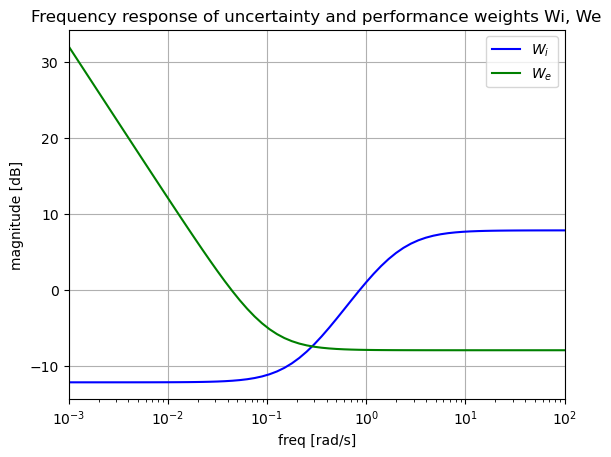

In [4]:
# Uncertainty block weight Wi
Wi = w_i.append(w_i) 
display("Uncertainty weight", Wi)

# Performance weight We (weight on S)
w_e = 0.8*ct.tf([0.5,0.05],[1,1e-6])
We = w_e.append(w_e)
display("Performance weight", We)

Wisv = rb.sigma(w_i, omega)
Wesv = rb.sigma(w_e, omega)

plt.semilogx(omega, 20*np.log10(Wisv[:, 0]), 'b', label=r'$W_i$')
plt.semilogx(omega, 20*np.log10(Wesv[:, 0]), 'g', label=r'$W_e$')
#plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e2])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Frequency response of uncertainty and performance weights Wi, We')

Uncertainty model with $\|\Delta\|_\infty<1$ approximately accounts for a 20% gain error and a neglected time delay of 0.9 (time is in minutes)


Construct the LFT

In [5]:
Wi.input_labels = ['u[0]', 'u[1]']
Wi.output_labels = ['zdelta[0]', 'zdelta[1]']
We.input_labels = ['y[0]', 'y[1]']
We.output_labels = ['z[0]', 'z[1]']
P.input_labels = ['up[0]','up[1]']
P.output_labels = ['yp[0]','yp[1]']

# Summing junction (multiplicative uncertainty)
sumdelta = ct.summing_junction(inputs=['u','wdelta'], output='up', dimension=2)

# Feedback: y = r-yp
fbk = ct.summing_junction(inputs=['w','-yp'], output='y', dimension=2)

# Generate the G transfer function of the LFT
G = ct.minreal(ct.interconnect([P, Wi, We, sumdelta, fbk],
                    inputs=['wdelta[0]','wdelta[1]','w[0]','w[1]','u[0]','u[1]'],
                    outputs=['zdelta[0]','zdelta[1]','z[0]','z[1]','y[0]','y[1]']), 
                    verbose=False)

Do $\mu$-synthesis.

INFO:DkIterFixedOrder:Iteration: 0, mu: 1.1763763427734375
INFO:DkIterFixedOrder:Iteration: 1, mu: 1.0076522827148438
INFO:DkIterFixedOrder:Iteration: 2, mu: 1.0041046142578125
INFO:DkIterFixedOrder:Iteration complete


'Peak upper bound (nubar): '

np.float64(1.0040201241052797)

Text(0.5, 1.0, '$\\bar\\mu$')

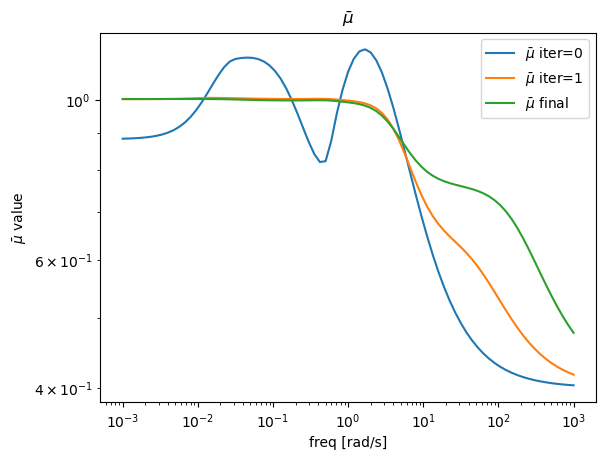

In [6]:
# Controller I/O sizes
f = 2

# Extended uncertainty structure: a 2x2 uncertainty block and a 2x2 performance block
nblock = np.array([2,2])
structure = np.array([[2,2],[2,2]])
# This has to be == 2 (complex uncertainty) for each block (other values are not implemented)
itype = np.array([2,2])

# Do mu-synthesis via old musyn implementation
# K, best_nubar, init_mubar, best_mubar, gamma = rb.musyn(G, f, nblock, itype, omega, maxiter=20)

# Do mu-synthesis using dkpy
logging.basicConfig(level=logging.INFO)

# Number of iterations
numiter = 2

# Do D-K iteration
K, best_nubar, iter_results = rb.musyn_dkpy(G, f, f, structure, omega, order=4, numiter=numiter)

# Close the loop and evaluate the mu upper bound for the obtained controller
K.input_labels = ['y[0]','y[1]']
K.output_labels = ['u[0]','u[1]']
M = ct.interconnect([P, K, Wi, We, sumdelta, fbk],
                    inputs=['wdelta[0]','wdelta[1]','w[0]','w[1]'],
                    outputs=['zdelta[0]','zdelta[1]','z[0]','z[1]'])

# Compute mu upper bound and its maximum over frequency
mubound, nubar = rb.mucomp(M, nblock, itype, omega)
display("Peak upper bound (nubar): ", nubar)

# Display the mu upper bound achieved throughout the iterations and the final one
for i in range(numiter):
    plt.loglog(omega, iter_results[i].mu_omega, label=r'$\bar \mu$ iter=%d' % i)
plt.loglog(omega, mubound, label=r'$\bar \mu$ final')

plt.ylabel(r'$\bar\mu$ value')
plt.xlabel('freq [rad/s]')
plt.legend()
plt.title(r'$\bar\mu$')

Verify performance on the nominal system. It must hold that $\|W_e S\|_\infty \leq 1$ since $\bar\nu\approx 1$. More precisely, we have $\|W_e S\|_\infty \leq \bar\nu$.

Text(0.5, 1.0, 'Singular values of S vs. nubar*inv(We) for the nominal system')

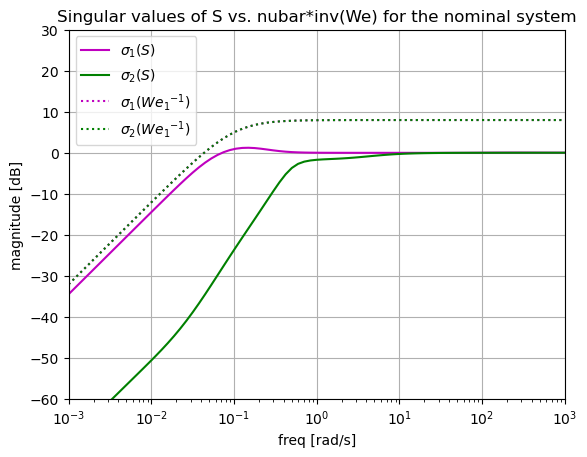

In [7]:
# Compute sensitivity for the nominal system
I = ct.ss([], [], [], np.eye(2)) # Identity system  
Delta = 0 * I
Delta.input_labels = ['zdelta[0]','zdelta[1]']
Delta.output_labels = ['wdelta[0]','wdelta[1]']               
K.input_labels = ['y[0]','y[1]']
K.output_labels = ['u[0]','u[1]'] 

S = ct.interconnect([P, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Ssv = rb.sigma(S, omega)

# Plot the singular values of gamma*invss(We) along with S
# for gamma = best_mu_upper_bound
Weinv = rb.invss(ct.ss(We))
Weinvsv = rb.sigma(Weinv, omega)

plt.semilogx(omega, 20*np.log10(Ssv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Ssv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 0]), 'm:', label=r'$\sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 1]), 'g:', label=r'$\sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. nubar*inv(We) for the nominal system')

Now we verify the performance under some admissible perturbations.

Text(0.5, 1.0, 'Singular values of S vs. nubar*inv(We) for perturbed system')

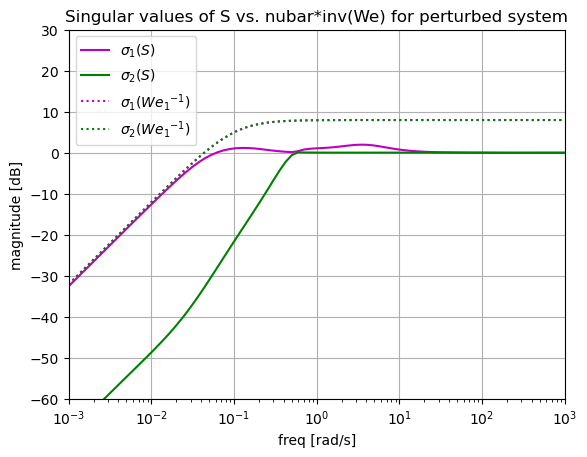

In [8]:
# Generate an admissible perturbed plant
tau = 0.5
g = -0.2
H = ct.tf([[[-tau/2*(1+g),1+g], [0]],
                  [[0], [-tau/2*(1+g),1+g]]],
                 [[[tau/2,1], [1]],
                  [[1], [tau/2,1]]])
# Perturbed plant
Pp = P * H
Pp.input_labels = ['up[0]','up[1]']
Pp.output_labels = ['yp[0]','yp[1]']

# Sensitivity of perturbed system
Sp = ct.interconnect([Pp, Delta, K, Wi, We, sumdelta, fbk],
                    inputs=['w[0]','w[1]'],
                    outputs=['y[0]','y[1]'], check_unused=False)

# Compute singular values of S over frequency
Spsv = rb.sigma(Sp, omega)

plt.semilogx(omega, 20*np.log10(Spsv[:, 0]), 'm', label=r'$\sigma_1(S)$')
plt.semilogx(omega, 20*np.log10(Spsv[:, 1]), 'g', label=r'$\sigma_2(S)$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 0]), 'm:', label=r'$\sigma_1({We_1}^{-1})$')
plt.semilogx(omega, 20*np.log10(Weinvsv[:, 1]), 'g:', label=r'$\sigma_2({We_1}^{-1})$')
plt.ylim([-60, 30])
plt.ylabel('magnitude [dB]')
plt.xlim([1e-3, 1e3])
plt.xlabel('freq [rad/s]')
plt.legend()
plt.grid()
plt.title('Singular values of S vs. nubar*inv(We) for perturbed system')

Text(0.5, 1.0, 'Closed loop responses to reference [1,1]')

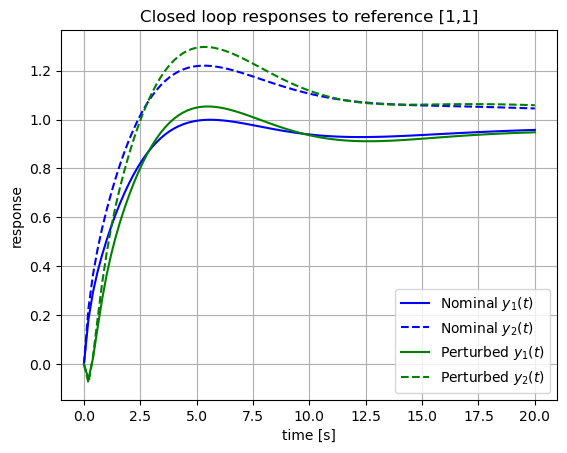

In [9]:
# Time for simulation
time = np.linspace(0, 20, 101)

# Compute complementary sensitivity for nominal and perturbed
T = I-S
Tp = I-Sp


# Compute and plot unit step responses
_, y1 = ct.step_response(T, time, input=0, squeeze=True)
_, y2 = ct.step_response(T, time, input=1, squeeze=True)
y = y1+y2
_, yp1 = ct.step_response(Tp, time, input=0, squeeze=True)
_, yp2 = ct.step_response(Tp, time, input=1, squeeze=True)
yp= (yp1+yp2)


plt.plot(time, y[0], 'b', label='Nominal $y_1(t)$')
plt.plot(time, y[1], 'b--', label='Nominal $y_2(t)$')
plt.plot(time, yp[0], 'g', label='Perturbed $y_1(t)$')
plt.plot(time, yp[1], 'g--', label='Perturbed $y_2(t)$')
plt.xlabel('time [s]')
plt.ylabel('response')
plt.legend()
plt.grid()
plt.title('Closed loop responses to reference [1,1]')
